![banner-pdi](https://user-images.githubusercontent.com/58775072/141189378-b5df3287-e8c0-48a1-ad11-825ba317463b.png)

## Universidade Federal de Campina Grande (UFCG)
## Centro de Engenharia Elétrica e Informática (CEEI) 
## Disciplina: Int. ao Processamento de Imagem Digital e Visão Computacional
## Professora: Luciana Ribeiro Veloso
## Aluno(a): Coloque seu nome aqui

## Observações
***

1. Os arquivos de laboratório devem ser salvos seguindo o seguinte padrão: `lab-x-nome-sobrenome.ipynb`.
2. Não esqueça de colocar o seu nome no cabeçalho acima.
3. Não altere a ordem das células e realize as implementações somente nos campos específicados.  
4. Ao longo do laboratório será solicitado perguntas teóricas relativas aos assuntos das aulas da disciplina e implementações de código utilizando a linguagem de programação Python. 
5. As células de implementação com código serão indicadas pelos seguintes comentários: `# IMPLEMENTE O SEU CÓDIGO AQUI`.
6. Para editar uma célula de texto, basta clicar duas vezes com o cursos do mouse para editar, e `Ctrl + Enter` para finalizar a edição. 
7. Para rodar as células com os códigos desenvolvidos, digite `Ctrl + Enter` ou clique em `Run` no menu do Jupyter.
8. Dúvidas, problemas de execução de código ou dificuldades com a linguagem de programação Python devem ser feitas durante as aulas de laboratório, encaminhadas para o grupo de WhatsApp da turma ou fórum do PVAE da disciplina.
9. Os laboratórios devem ser enviados nos campos especificados pelo PVAE. ATENTE-SE AOS PRAZOS DE ENTREGA!

# <span style='color:red'>Laboratório 4: Morfologia Matemática</span>
***

### Importação dos Pacotes

In [1]:
import os                            # operational system para manipulação de arquivos
import cv2                           # opencv para manipulação de imagens
import numpy as np                   # numpy para manipulação de matrizes e arrays
import matplotlib.pyplot as plt      # pyplot para plotagem de gráficos e imagens
import skimage.morphology            # scikit-image para produzir elementos estruturantes
import urllib.request as url         # urllib para baixar arquivos via HTTPS
import zipfile                       # zipfile para lidar com pastas compactadas

In [2]:
# baixando as imagens de referência
url.urlretrieve('https://github.com/Alyssonmach/pdi-labs/raw/main/imagens.zip', 'imagens.zip')
with zipfile.ZipFile('imagens.zip', 'r') as zip_ref:
    zip_ref.extractall('')

### Operações Lógicas em Imagens Binárias

É possível submeter imagens a operações lógicas de modo a obter novas imagens. Nesse contexto, a biblioteca OpenCV disponibiliza um conjunto de funções para implementação dessas operações:

1. AND: **C = A $\cap$ B**   
    * `C = cv2.bitwise_and( A, B )`
2. OR: $C = A \cup B$   
    * `C = cv2.bitwise_or( A, B )`
3. XOR: $C = A \oplus B$   
    * `C = cv2.bitwise_xor( A, B )`
4. Not: $C = \overline{A}$   
    * `C = ~A`
5. Diferença: $C = A \cap \overline{B} $   
    *  `C = A - B` 
    
    
**Obs:** a função `cv2.threshold( src_img, limiar, vmax, cv2.THRESH_BINARY)` pode ser utilizada para binarizar imagens de tipo `uint`, sendo necessário informar o limiar de binarização e o valor do nível alto. A função retorna o limiar utilizado e a imagem binarizada, com pixels de nível alto setados para `vmax` e os demais para 0.

## <span style='color:blue'>Questão 1: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Carregue as imagens “**A.tif**” e “**B.tif**”. Faça uma binarização e realize as operações abaixo. Plote os resultados e os comente.

    * 1. $A$  
    * 2. $B$  
    * 3. $C = A \cap B$ 
    * 4. $D = A - B$   
    * 5. $E = \overline{A}$    
    * 6. $F = \overline{B}$  
    * 7. $G = A \cup B$  
    * 8. $H = B - A$ 

Text(0.5, 0, 'Dimensões (313, 316)')

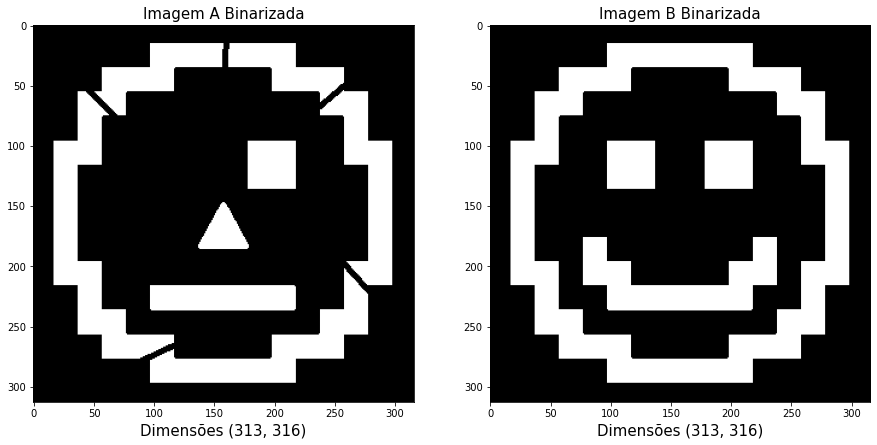

In [3]:
ima = cv2.imread('imagens/A.tif')
ima = cv2.cvtColor(ima, cv2.COLOR_BGR2GRAY)
imb = cv2.imread('imagens/B.tif')
imb = cv2.cvtColor(imb, cv2.COLOR_BGR2GRAY)
 
# aplicando a binarização nas imagens carregadas
ima_bin = cv2.threshold( ima, 127.5, 255, cv2.THRESH_BINARY)[1]
imb_bin = cv2.threshold( imb, 127.5, 255, cv2.THRESH_BINARY)[1]

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (15, 15))

# primeira figura da subplotagem
axs[0].imshow(ima_bin, cmap = 'gray', vmin = np.min(ima_bin), vmax = np.max(ima_bin))
axs[0].set_title('Imagem A Binarizada', size = 15)
axs[0].set_xlabel('Dimensões ' + str(ima_bin.shape), size = 15)

# segunda figura da subplotagem
axs[1].imshow(imb_bin, cmap = 'gray', vmin = np.min(imb_bin), vmax = np.max(imb_bin))
axs[1].set_title('Imagem B Binarizada', size = 15)
axs[1].set_xlabel('Dimensões ' + str(imb_bin.shape), size = 15) 

Text(0.5, 0, 'Dimensões (313, 316)')

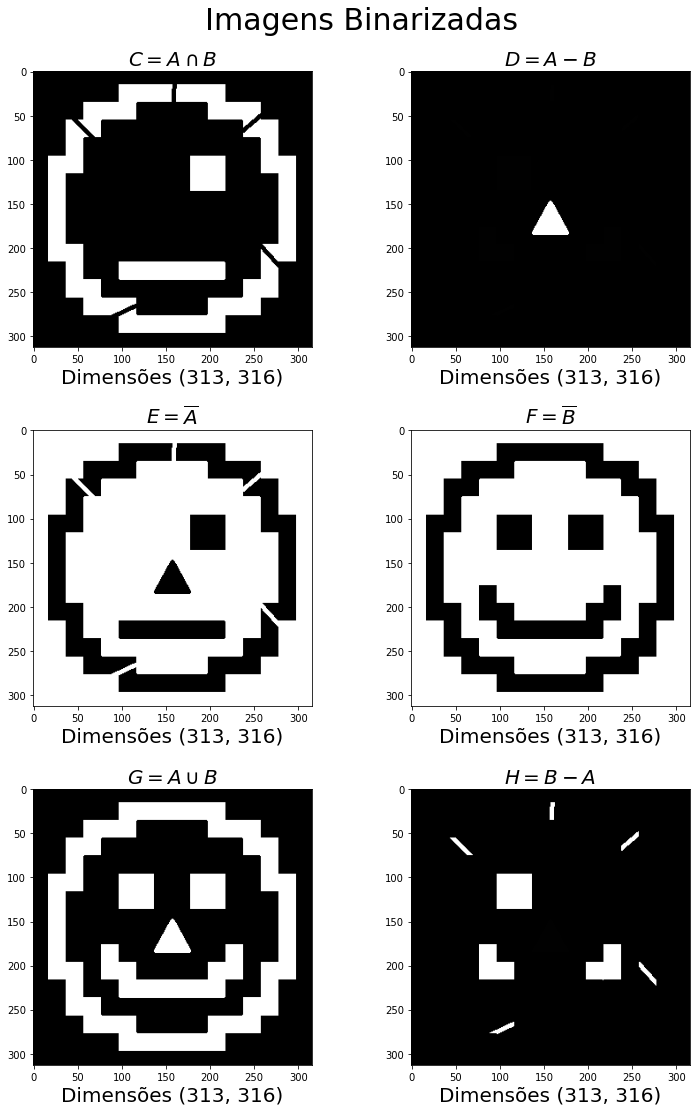

In [4]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 1
# operação lógica 3
imc = cv2.bitwise_and(ima_bin, imb_bin) # adice a operação aqui
# operação lógica 4
imd = ima_bin - imb_bin # adicione a operação aqui
# operação lógica 5
ime = ~ima_bin  # adicione a operação aqui
# operação lógica 6
imf = ~imb_bin  # adicione a operação aqui
# operação lógica 7
img = cv2.bitwise_or(ima_bin, imb_bin) # adicione a operação aqui
# operação lógica 8
imh = imb_bin - ima_bin   # adicione a operação aqui

fig, axs = plt.subplots(nrows = 3, ncols = 2, figsize = (15, 15))
plt.subplots_adjust(left = 0, bottom = 0, right = 0.7, top = 0.92, wspace = 0, hspace = 0.3)
fig.suptitle('Imagens Binarizadas', size = 30, x = 0.35) 

# primeira figura da subplotagem
axs[0,0].imshow(imc, cmap='gray', vmin = np.min(imc), vmax = np.max(imc))
axs[0,0].set_title('$C = A \cap B$', size = 20)
axs[0,0].set_xlabel('Dimensões ' + str(imc.shape), size = 20)

# segunda figura da subplotagem
axs[0,1].imshow(imd, cmap='gray', vmin = np.min(imd), vmax = np.max(imd))
axs[0,1].set_title('$D = A - B$ ', size = 20)
axs[0,1].set_xlabel('Dimensões ' + str(imd.shape), size = 20)

# terceira figura da subplotagem
axs[1,0].imshow(ime, cmap='gray', vmin=np.min(ime), vmax=np.max(ime))
axs[1,0].set_title('$E = \overline{A}$', size=20)
axs[1,0].set_xlabel('Dimensões ' + str(ime.shape), size=20)

# quarta figura da subplotagem
axs[1,1].imshow(imf, cmap='gray', vmin = np.min(imf), vmax = np.max(imf))
axs[1,1].set_title('$F = \overline{B}$', size = 20)
axs[1,1].set_xlabel('Dimensões ' + str(imf.shape), size = 20)

# quinta figura da subplotagem
axs[2,0].imshow(img, cmap='gray', vmin = np.min(img), vmax = np.max(img))
axs[2,0].set_title('$G = A \cup B$', size = 20)
axs[2,0].set_xlabel('Dimensões ' + str(img.shape), size = 20)

# sexta figura da subplotagem
axs[2,1].imshow(imh, cmap = 'gray', vmin = np.min(imh), vmax = np.max(imh))
axs[2,1].set_title('$H = B - A$', size = 20)
axs[2,1].set_xlabel('Dimensões ' + str(imh.shape), size = 20) 

## <span style='color:green'>Respostas da Questão 1:</span>

* Observando os resultados de cada uma das imagens, é possível destacar que:

    * 1. $A$: Imagem A binarizada. 
    * 2. $B$: Imagem B binarizada.  
    * 3. $C = A \cap B$: Pixels altos de A binarizada e pixels altos de B binarizada compostos pela intersecção dos seus valores. Como a imagem A binarizada está parcialmente contida em B binarizada (exceto pelo triângulo que sugere ser um nariz), temos que a saída é A binarizada sem o triângulo na região do nariz.   
    * 4. $D = A - B$: Pixels da imagem A binarizada subtraídos dos pixels da imagem B binarizada. Como a única região de pixels com valores altos de A é a que forma um triângulo, e essa não está presente nos pixels B binarizada (como visto no procedimento 3), os pixels dessa região será o resultado da subtração realizada.     
    * 5. $E = \overline{A}$: Pixels com valores altos da imagem A binarizada passam a ter valores baixos e vice-versa.  
    * 6. $F = \overline{B}$: Pixels com valores altos da imagem B binarizada passam a ter valores baixos e vice-versa.  
    * 7. $G = A \cup B$: A união dos pixels da imagem A binarizada com os pixels da imagem B binarizada. Como saída dessa operação, foi obtido todos os pixels altos da Imagem B binarizada com os pixels que formam um triângulo da imagem A binarizada.  
    * 8. $H = B - A$: Semelhante ao procedimento 4, mas agora mudando a ordem dos fatores, temos uma mudança no resultado, visto que a subtração não é uma operação comutativa. Tendo em visto isso, o resultado desse procedimento é todos os valores de pixels altos presentes na imagem B binarizada que não estão presentes na imagem A binarizada.

## <span style='color:blue'>Questão 2: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* O código abaixo aplica uma das máscaras binárias da questão anterior sobre uma imagem. Com relação à imagem resultante, responda:
 * (a) Qual o efeito de aplicar uma máscara binária sobre uma imagem?
 * (b) Cite pelo menos duas possíveis aplicações dessa operação. Qual o papel das máscaras nessas aplicações?
 * (c) Tendo em vista a quantidade de tons de cinza na máscara, qual a importância do tipo de interpolação utilizado?  

Text(0.5, 1.0, 'Imagem Resultante')

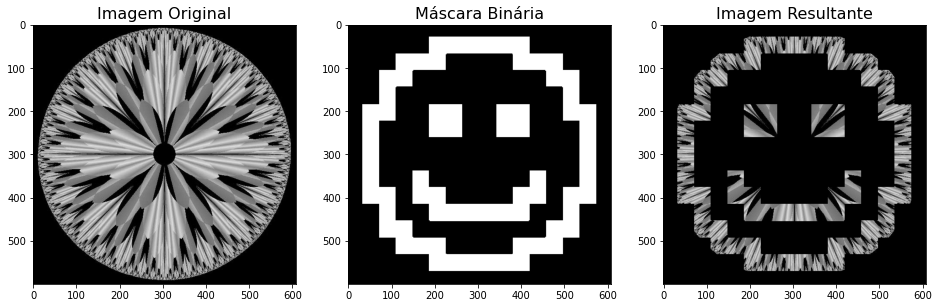

In [5]:
# imagem mandala
mandala = cv2.imread( os.path.join(".", "imagens", "mandala.jpg"), 0 )
H, W = mandala.shape

# imagem b
B = cv2.imread( os.path.join(".", "imagens", "B.tif"), 0 )
_, B = cv2.threshold(B, 127, 255, cv2.THRESH_BINARY)
B_resized = cv2.resize(B, (W, H), interpolation = cv2.INTER_NEAREST)

# imagem d
combined = cv2.bitwise_and( mandala, B_resized )

# plotagem
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(16, 8))

# primeira subfigura da primeira linha
axs[0].imshow(mandala, vmin=0, vmax=255, cmap="gray")
axs[0].set_title("Imagem Original", fontsize = 16)

# segunda subfigura da primeira linha
axs[1].imshow(B_resized, vmin=0, vmax=255, cmap="gray")
axs[1].set_title("Máscara Binária", fontsize = 16)

# terceira subfigura da primeira linha
axs[2].imshow(combined, vmin=0, vmax=255, cmap="gray")
axs[2].set_title("Imagem Resultante", fontsize = 16)

## <span style='color:green'>Respostas da Questão 02:</span>
* (a) A aplicação de mascáras binárias em imagens permite destacar determinadas regiões conhecidas na imagem. Desse modo, apenas as informações relevantes serão visualizáveis e as não importantes ocultadas.
* (b) Adição de personagens em cenários nos jogos 2D: a função da máscara binária nessa aplicação é juntar imagens de personagens do game com diversos cenários, dando a sensação de diversidade das fases ao jogador; Segmentação de objetos em imagens: uma forma interessante de segmentação de imagens utilizando redes neurais convolucionais é utilizar modelos que predizem máscaras binárias sobre a classe em análise.
* (c) A interpolação exerce uma fundamental importância na hora de redimensionar a imagem, pois esse procedimento permite usar dados conhecidos (os pixels da imagem em sua dimensão original) para estimar dados desconhecidos, esses que são resultados no processo de aumentar ou diminuir uma imagem. No exemplo analisado, a imagem foi ampliada e o tipo de interpolação utilizada usa os pixels vizinhos para estimar a localização de novos pixels, permitindo com que a imagem mantenha a mesma qualidade, principalmente ao se considerar a baixa quantidade de tons de cinza na máscara gerada.

### Transformações Lineares

Também é possível realizar transformações lineares como rotação e translação com o OpenCV. Para isso, faz-se uso da função **warpAffine**.

`dst_img = cv2.warpAffine(src_img, M, (cols, rows))`

Descrição:  
* **dst_img** representa a imagem de saída;
* **src_img** representa a imagem de entrada;
* **M** corresponde à matriz de transformação utilizada;
* **rows** corresponde ao número de linhas da imagem;
* **cols** corresponde ao número de colunas da imagem;

Alguns exemplos de transformações que podem ser produzidas a partir desta função são:

1. Translações:
    * Para transladar a imagem Tx pixels para a direita e Ty pixels para baixo, faz-se uso de uma matriz com forma: 
    * **M = [ [1, 0, Tx], [0, 1, Ty] ]**
2. Rotações:
    * A matriz de transformação para uma rotacão de $\theta$ graus com relação ao ponto (Px, Py) pode ser obtida utilizando a função **getRotationMatrix2D**: 
    * `M = cv2.getRotationMatrix2D( (Px, Py), $\theta$, scale)`
3. Reflexão:
    * A imagem pode ser refletida utilizando as seguintes matrizes: 
    * **M = [ [-1, 0, cols-1], [0, 1, 0] ]**
    * **M = [ [1, 0, 0], [0, -1, rows-1] ]**

## <span style='color:blue'>Questão 3: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* (a) O código abaixo implementa algumas das transformações descritas. Comente todas as linhas desse código e explique o que o programa faz.
* (b) Que transformações são implementadas pelas matrizes Ma, Mb, Mc e Md?
* (c) As imagens 2 e 4 são diferentes apesar de terem sofrido as mesmas transformações. Por que isso aconteceu?

Text(0.5, 1.0, 'Imagem 6')

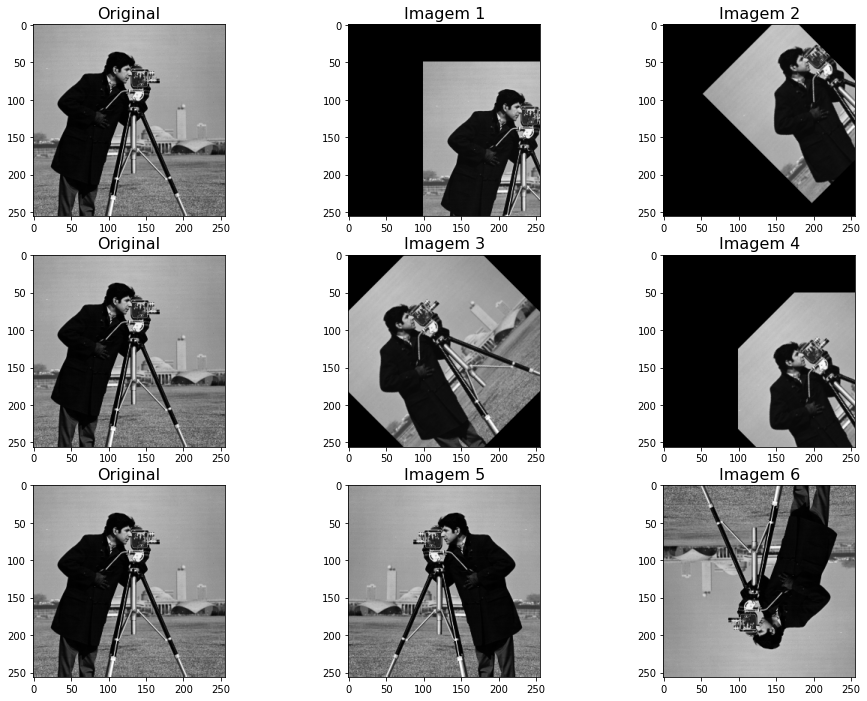

In [6]:
# COMENTE AS LINHAS QUE CÓDIGO ABAIXO --> QUESTÃO 3 - LETRA (a)
# configurando o parâmetro que permite transladar 100 pixels para a direita
Tx    = 100
# configurando o parâmetro que permite transladar 50 pixels para baixo
Ty    =  50
# configurando o parâmetro de rotação da imagem a 45 graus.
theta =  45

# encontrando a imagem de análise no diretório correspondente
src_img = cv2.imread(os.path.join(".", "imagens", "cameraman.jpg"), 0)
# obtendo a quantidade de linhas e colunas da matriz de pixels da imagem
rows, cols = src_img.shape

# matriz de transformação linear para transladar imagens
Ma = np.array( [ [1, 0, Tx], [0, 1, Ty] ], dtype=np.float32 )
# matriz de transformação linear para rotacionar imagens
Mb = cv2.getRotationMatrix2D( (cols/2, rows/2),  theta , 1)
# matriz de transformação linear para refletir imagens horizontalmente
Mc = np.array( [[-1, 0, cols-1], [0, 1, 0]], dtype = np.float32 )
# matriz de transformação linear para refletir imagens verticalmente
Md = np.array( [[1, 0, 0], [0, -1, rows-1]], dtype = np.float32 )

# Plots
fig, axs = plt.subplots(nrows = 3, ncols = 3, figsize=(16, 12))

# primeira subfigura da primeira linha
axs[0][0].imshow(src_img, cmap="gray")
axs[0][0].set_title("Original", fontsize = 16)

# segunda Ssubfigura da primeira linha
dst_img = cv2.warpAffine(src_img, Ma, (cols, rows))
axs[0][1].imshow(dst_img, cmap="gray")
axs[0][1].set_title("Imagem 1", fontsize = 16)

# terceira subfigura da primeira linha
dst_img = cv2.warpAffine(dst_img, Mb, (cols, rows))
axs[0][2].imshow(dst_img, cmap="gray")
axs[0][2].set_title("Imagem 2", fontsize = 16)

# primeira subfigura da segunda linha
axs[1][0].imshow(src_img, cmap="gray")
axs[1][0].set_title("Original", fontsize = 16)

# segunda subfigura da segunda linha
dst_img = cv2.warpAffine(src_img, Mb, (cols, rows))
axs[1][1].imshow(dst_img, cmap="gray")
axs[1][1].set_title("Imagem 3", fontsize = 16)

# terceira subfigura da segunda linha
dst_img = cv2.warpAffine(dst_img, Ma, (cols, rows))
axs[1][2].imshow(dst_img, cmap="gray")
axs[1][2].set_title("Imagem 4", fontsize = 16)

# primeira subfigura da terceira linha
axs[2][0].imshow(src_img, cmap="gray")
axs[2][0].set_title("Original", fontsize = 16)

# segunda subfigura da terceira linha
dst_img = cv2.warpAffine(src_img, Mc, (cols, rows))
axs[2][1].imshow(dst_img, cmap="gray")
axs[2][1].set_title("Imagem 5", fontsize = 16)

# terceira subfigura da terceira linha
dst_img = cv2.warpAffine(dst_img, Md, (cols, rows))
axs[2][2].imshow(dst_img, cmap="gray")
axs[2][2].set_title("Imagem 6", fontsize = 16)

## <span style='color:green'>Respostas da Questão 03:</span>

* (b) Que transformações são implementadas pelas matrizes Ma, Mb, Mc e Md?
    * **Ma**: matriz de transformação linear para transladar imagens.
    * **Mb**: matriz de transformação linear para rotacionar imagens.
    * **Mc**: matriz de transformação linear para refletir imagens horizontalmente.
    * **Md**: matriz de transformação linear para refletir imagens verticalmente.

* (c) As imagens 2 e 4 são diferentes apesar de terem sofrido as mesmas transformações. Por que isso aconteceu?
    * Mesmo sofendo as mesmas transformações, as imagens 2 e 4 são diferentes, pois a ordem em que a transformação foi aplicada nas imagens não foi a mesma.
        * Imagem original -> imagem transladada -> imagem rotacionada -> Imagem 2 (1)  
        * Imagem original -> imagem rotacionada -> imagem transladada -> Imagem 4 (2)
    * Na primeira transformação linear aplicada em ambas imagens, as informações de entrada são iguais, mas as saídas são distintas, pois as matrizes de transformação utilizadas foram as de translação e rotação, respectivamente.
    * Na segunda transformação linear aplicada em ambas as imagens, as informações de entrada e saída são distintas. Além disso, as matrizes de transformação utilizadas foram as de rotação e translação, respectivamente.
    * Desse modo, comparando cada um dos passos que formaram as imagens 2 e 4, elas só são iguais nas imagens de entrada para a primeira transformação.

## <span style='color:blue'>Questão 4: [Valor da Questão: 1.5][Taxa de acerto: x.x]</span>

* Abra a imagem "**Seta.tif**", realize operações abaixo e comente os resultados obtidos.
 * Translação de -50 pixels na horizontal e   0 pixels na vertical.
 * Translação de 125 pixels na horizontal e -75 pixels na vertical.
 * Reflexão horizontal.
 * Reflexão vertical.
 * Rotação de -25° com relação ao ponto (x =  59, y =  78) e escala   1.
 * Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala   3.
 * Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala 1/3.
 * Rotação de   0° com relação ao ponto (x =  59, y =  59) e escala 1/4.

Text(0.5, 1.0, 'Imagem 8')

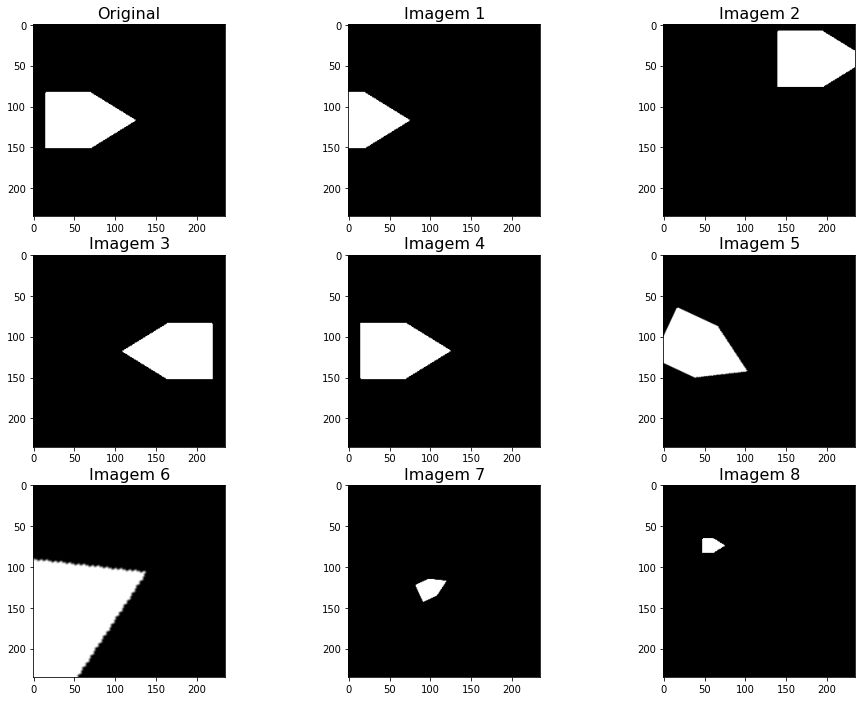

In [7]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 4
def make_translation(input_image, tx, ty):
    '''função auxiliar para realizar transformação linear de translação'''
    
    mat_trans = np.array([ [1, 0, tx], [0, 1, ty] ], dtype=np.float32)
    
    return cv2.warpAffine(input_image, mat_trans, input_image.shape) 

def make_rotation(input_image, x, y, theta, scale):
    '''função auxiliar para realizar transformação linear de rotação'''
    
    mat_trans = cv2.getRotationMatrix2D((x, y),  theta , scale)
    
    return cv2.warpAffine(input_image, mat_trans, input_image.shape)  

def make_reflection(input_image, label = 'x'):
    '''função auxiliar para realizar transformação linear de reflexão '''
    
    rows, cols = input_image.shape[0], input_image.shape[1]
    
    if label == 'y': mat_trans = np.array([[1, 0, 0], [0, -1, rows-1]], dtype = np.float32)
    else: mat_trans = np.array([[-1, 0, cols-1], [0, 1, 0]], dtype = np.float32)
        
    return cv2.warpAffine(input_image, mat_trans, input_image.shape)

# carregando a imagem e convertendo para a escala de cinza 
im_seta = cv2.imread('imagens/Seta.tif')
im_seta = cv2.cvtColor(im_seta, cv2.COLOR_BGR2GRAY)
im_seta = cv2.threshold(im_seta, 127.5, 255, cv2.THRESH_BINARY)[1] 

# aplicando as transformações lineares na imagem em análise  
im1 = make_translation(im_seta, -50, 0)
im2 = make_translation(im_seta, 125, -75)
im3 = make_reflection(im_seta, 'x')
im4 = make_reflection(im_seta, 'y')
im5 = make_rotation(im_seta, 59, 78, -25, 1)
im6 = make_rotation(im_seta, 118, 118, 25, 3)
im7 = make_rotation(im_seta, 118, 118, 25, 1/3)
im8 = make_rotation(im_seta, 59, 59, 0, 1/4)

fig, axs = plt.subplots(nrows = 3, ncols = 3, figsize=(16, 12))

# primeira figura da subplotagem
axs[0][0].imshow(im_seta, cmap="gray")
axs[0][0].set_title("Original", fontsize = 16)

# segunda figura da subplotagem
axs[0][1].imshow(im1, cmap="gray")
axs[0][1].set_title("Imagem 1", fontsize = 16)

# terceira figura da subplotagem
axs[0][2].imshow(im2, cmap="gray")
axs[0][2].set_title("Imagem 2", fontsize = 16)

# quarta figura da subplotagem
axs[1][0].imshow(im3, cmap="gray")
axs[1][0].set_title("Imagem 3", fontsize = 16)

# quinta figura da subplotagem
axs[1][1].imshow(im4, cmap="gray")
axs[1][1].set_title("Imagem 4", fontsize = 16)

# sexta figura da subplotagem
axs[1][2].imshow(im5, cmap="gray")
axs[1][2].set_title("Imagem 5", fontsize = 16)

# sétima figura da subplotagem
axs[2][0].imshow(im6, cmap="gray")
axs[2][0].set_title("Imagem 6", fontsize = 16)

# oitava figura da subplotagem
axs[2][1].imshow(im7, cmap="gray")
axs[2][1].set_title("Imagem 7", fontsize = 16)

# nona figura da subplotagem
axs[2][2].imshow(im8, cmap="gray")
axs[2][2].set_title("Imagem 8", fontsize = 16)

## <span style='color:green'>Respostas da Questão 4:</span>

* Esses conjuntos de transformações na imagem em que a sua geometria é alterada sem modificar os valores reais de pixel é comumente referido como transformação “geométrica”. No geral, foi utilizado diversas transformações, mas os valores reais dos pixels permaneceram inalterados. Tais procedimentos podem variar de acordo com a forma e a finalidade das matrizes de transformação.

* Legenda das plotagens:

    * **Imagem 1**: Translação de -50 pixels na horizontal e   0 pixels na vertical.
    * **Imagem 2**: Translação de 125 pixels na horizontal e -75 pixels na vertical.
    * **Imagem 3**: Reflexão horizontal.
    * **Imagem 4**: Reflexão vertical.
    * **Imagem 5**: Rotação de -25° com relação ao ponto (x =  59, y =  78) e escala   1.
    * **Imagem 6**: Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala   3.
    * **Imagem 7**: Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala 1/3.
    * **Imagem 8**: Rotação de   0° com relação ao ponto (x =  59, y =  59) e escala 1/4.

### Dilatação e Erosão

A partir de um elemento estruturante é possível utilizar funções do OpenCV para realizar as transformações morfológicas de erosão (1) e dilatação (2). A sintaxe das funções é: 

 1. `dst_img = cv2.erode( src_img, kernel, iterations = 1 )`    
 2. `dst_img = cv2.dilate( src_img, kernel, iterations = 1 )`   

* **Descrição:**  
    * **dst_img** representa a imagem de saída;
    * **src_img** representa a imagem de entrada;
    * **kernel** representa o elemento estruturante;
    * **iterations** corresponde ao número de vezes que a operação deve ser repetida.

Elementos estruturantes podem ser produzidos a partir de arrays do numpy.

## <span style='color:blue'>Questão 5: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Carregue a imagem "**text.tif**" e utilize o elemento estruturante abaixo para produzir uma versão dilatada da imagem e outra versão erodida. Comente os resultados encontrados.
    * `kernel = np.array([[1, 0, 1], [0, 1, 0], [1, 0, 1]], dtype = np.uint8)`

Text(0.5, 1.0, 'Imagem Erodida')

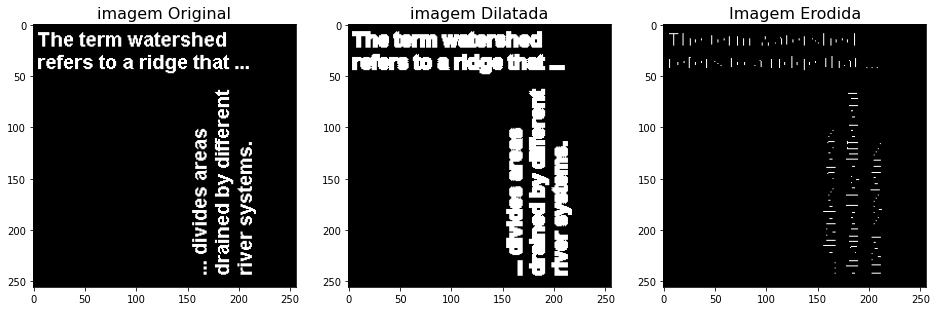

In [8]:
## IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 5
# carregando a imagem na escala de cinza
im_text = cv2.imread('imagens/text.tif')
im_text = cv2.cvtColor(im_text, cv2.COLOR_BGR2GRAY)
im_text = cv2.threshold(im_text, 127.5, 255, cv2.THRESH_BINARY)[1]

# definindo o elemento estruturante 
kernel = np.array([[1, 0, 1], [0, 1, 0], [1, 0, 1]], dtype = np.uint8)

# aplicando uma dilatação utilizando o elemento estrutural
im_dilate = cv2.dilate(im_text, kernel, iterations = 1)
# aplicando uma erosão utilizando o elemento estrutural
im_erode = cv2.erode(im_text, kernel, iterations=1)

fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (16, 12))

# primeira figura da subplotagem
axs[0].imshow(im_text, cmap = "gray")
axs[0].set_title("imagem Original", fontsize = 16)

# segunda figura da subplotagem
axs[1].imshow(im_dilate, cmap ="gray")
axs[1].set_title("imagem Dilatada", fontsize = 16)

# terceira figura da subplotagem
axs[2].imshow(im_erode, cmap = "gray")
axs[2].set_title("Imagem Erodida", fontsize = 16)

## <span style='color:green'>Respostas da Questão 5:</span>

* O efeito de aplicar a dilatação na imagem acima "engordou" os detalhes presentes na borda dos caracteres (considerando-os como partículas), o que dificultou a compreensão do texto presente na imagem.
* O efeito de aplicar a erosão na imagem acima removeu os detalhes presentes na borda dos caracteres (considerando-os como partículas), o que os descaracterizou completamente.

Elementos estruturantes também podem ser produzidos pela função **getStructuringElement** do OpenCV:

 * `kernel = cv2.getStructuringElement( FLAG, (W,H) )`

* **Descrição:**
    * **kernel** representa o elemento estruturante;
    * **(W, H)** é uma tupla com as dimensões do elemento estruturante;
    * **FLAG** é um parâmetro que indica o tipo de elemento estruturante produzido, pode ser:
        * **cv2.MORPH_RECT** produz um elemento retangular;
        * **cv2.MORPH_ELLIPSE** produz um elemento elíptico;
        * **cv2.MORPH_CROSS** produz um elemento em forma de cruz;

Text(0.5, 1.0, 'cv2.MORPH_CROSS')

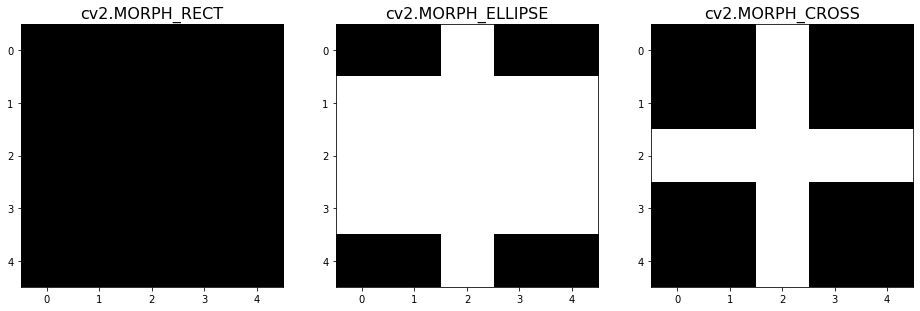

In [9]:
H, W = 5, 5

# plots
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (16, 12))

# primeira Subfigura da primeira linha
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (W, H))
axs[0].imshow(kernel, cmap = "gray")
axs[0].set_title("cv2.MORPH_RECT", fontsize = 16)

# segunda Subfigura da primeira linha
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (W, H))
axs[1].imshow(kernel, cmap = "gray")
axs[1].set_title("cv2.MORPH_ELLIPSE", fontsize = 16)

# terceira Subfigura da primeira linha
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (W, H))
axs[2].imshow(kernel, cmap = "gray")
axs[2].set_title("cv2.MORPH_CROSS", fontsize = 16)

Ou ainda utilizando as funções do Scikit-Image:

 * `kernel = skimage.morphology.square( H )`
 * `kernel = skimage.morphology.rectangle( H, W )`
 * `kernel = skimage.morphology.diamond( H )`
 * `kernel = skimage.morphology.disk( R )`
 * `kernel = skimage.morphology.octagon( M, N )`
 * `kernel = skimage.morphology.star( A)`

Text(0.5, 1.0, 'Star')

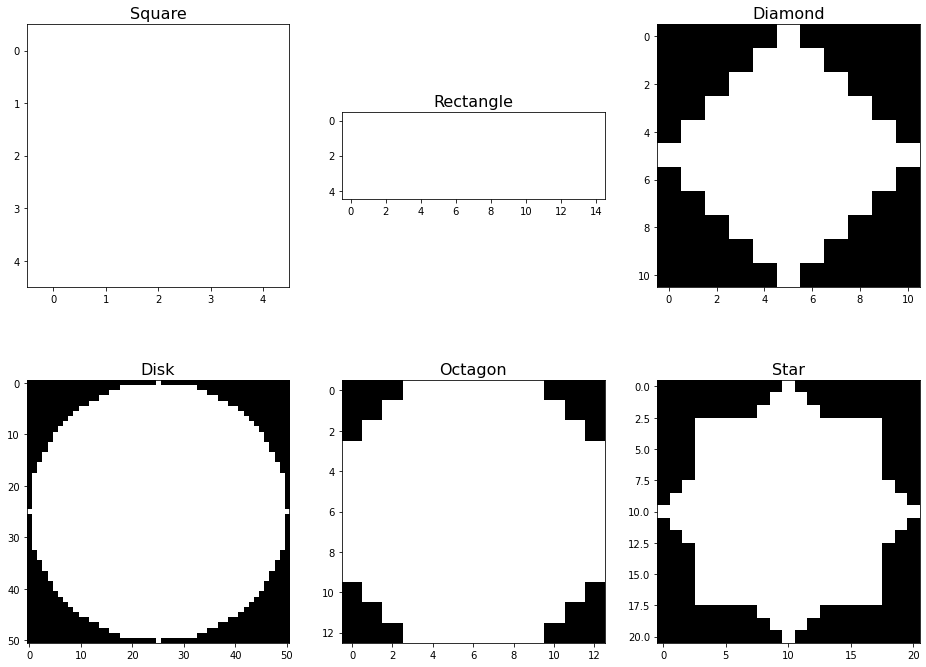

In [10]:
H =  5 # altura do quadrado/retângulo e lado do diamante
W = 15 # largura do retângulo
R = 25 # raio do disco
M =  7 # comprimento dos lados retos do octágono
N =  3 # comprimento dos lados inclinados do octágono
A =  7 # variável que controla o tamanho da estrela, o quadrado que a contém tem lado H = 2 * a + 1 + 2 * floor(a / 2) 

# plots
fig, axs = plt.subplots(nrows = 2, ncols = 3, figsize=(16, 12))

# primeira Subfigura da primeira linha 
kernel = skimage.morphology.square(H)
axs[0][0].imshow(kernel, vmin = 0, vmax = 1, cmap = "gray")
axs[0][0].set_title("Square", fontsize = 16)

# segunda Subfigura da primeira linha
kernel = skimage.morphology.rectangle(H, W)
axs[0][1].imshow(kernel, vmin = 0, vmax = 1, cmap = "gray")
axs[0][1].set_title("Rectangle", fontsize = 16)

# terceira Subfigura da primeira linha
kernel = skimage.morphology.diamond(H)
axs[0][2].imshow(kernel, vmin = 0, vmax = 1, cmap = "gray")
axs[0][2].set_title("Diamond", fontsize = 16)

# primeira Subfigura da segunda linha
kernel = skimage.morphology.disk(R)
axs[1][0].imshow(kernel, vmin = 0, vmax = 1, cmap = "gray")
axs[1][0].set_title("Disk", fontsize = 16)

# segunda Subfigura da segunda linha
kernel = skimage.morphology.octagon(M, N)
axs[1][1].imshow(kernel, vmin = 0, vmax = 1, cmap = "gray")
axs[1][1].set_title("Octagon", fontsize = 16)

# terceira Subfigura da segunda linha
kernel = skimage.morphology.star(A)
axs[1][2].imshow(kernel, vmin = 0, vmax = 1, cmap = "gray")
axs[1][2].set_title("Star", fontsize = 16)

Text(0.5, 1.0, 'Linha Vertical de 5 pontos')

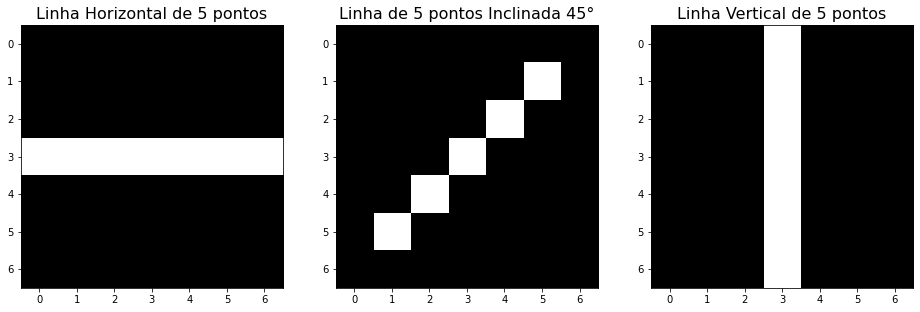

In [11]:
# elemento estruturante correspondente a uma linha horizontal
orig_kernel  = np.zeros((7, 7), dtype = np.uint8)
orig_kernel[3, :] = 1

# matriz de rotação para 45°
M = cv2.getRotationMatrix2D((3, 3), 45, 1)

# plots
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(16, 12))

# primeira subfigura da primeira linha
axs[0].imshow(orig_kernel, cmap = "gray")
axs[0].set_title("Linha Horizontal de 5 pontos", fontsize = 16)

# segunda subfigura da primeira linha
kernel = cv2.warpAffine(orig_kernel, M, (7, 7))
axs[1].imshow(kernel, cmap = "gray")
axs[1].set_title("Linha de 5 pontos Inclinada 45°", fontsize = 16)

# terceira subfigura da primeira linha
kernel = cv2.warpAffine(kernel, M, (7, 7))
axs[2].imshow(kernel, cmap = "gray")
axs[2].set_title("Linha Vertical de 5 pontos", fontsize = 16) 

## <span style='color:blue'>Questão 6: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Usando as funções mostradas, gere os seguintes elementos estruturantes para dilatar a imagem 'text.tif'. Mostre as imagens resultantes e comente os resultados encontrados.
 * Disco de raio 9;
 * Estrela com A = 13;
 * Linha vertical de 11 pontos de tamanho;
 * Linha vertical de 9 pontos de tamanho;

Text(0.5, 1.0, 'Linha Vertical de 9 pontos')

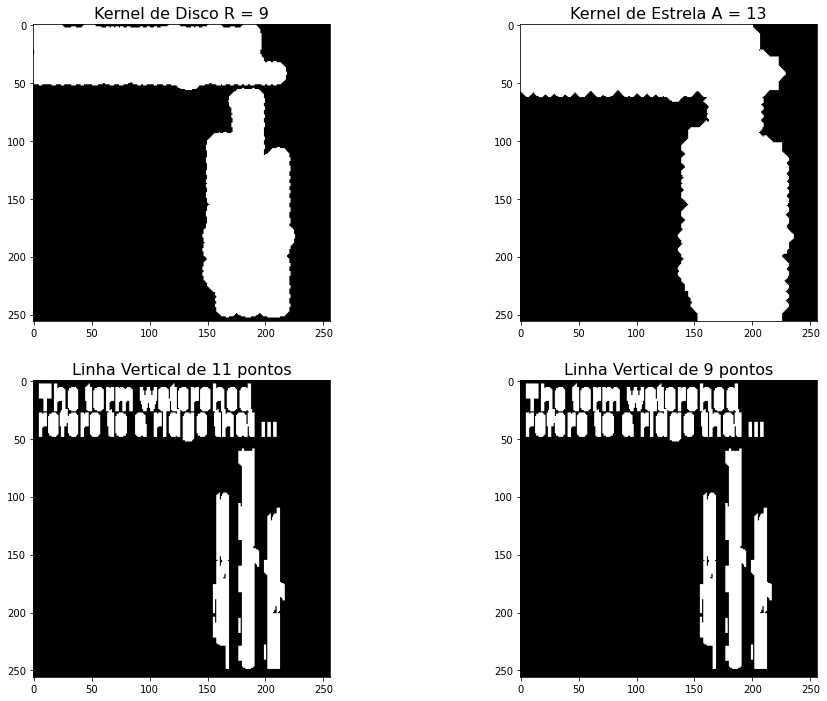

In [12]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 6
# gerando elementos estruturantes 
disk_kernel = kernel = skimage.morphology.disk(9)
star_kernel = skimage.morphology.star(13)
vertical_line1 = np.zeros((11, 11), dtype = np.uint8)
vertical_line1[:, 5] = 1
vertical_line2 = np.zeros((9, 9), dtype = np.uint8)
vertical_line2[:, 4] = 1

# aplicando a dilatação na imagem utilizando os diversos elementos estruturantes propostos 
im1_dilate = cv2.dilate(im_text, disk_kernel, iterations = 1)
im2_dilate = cv2.dilate(im_text, star_kernel, iterations = 1)
im3_dilate = cv2.dilate(im_text, vertical_line1, iterations = 1)
im4_dilate = cv2.dilate(im_text, vertical_line2, iterations = 1)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))

# primeira figura da subplotagem
axs[0, 0].imshow(im1_dilate, cmap = "gray")
axs[0, 0].set_title("Kernel de Disco R = 9", fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(im2_dilate, cmap = "gray")
axs[0, 1].set_title("Kernel de Estrela A = 13", fontsize = 16) 

# terceira figura da subplotagem
axs[1, 0].imshow(im3_dilate, cmap = "gray")
axs[1, 0].set_title("Linha Vertical de 11 pontos", fontsize = 16)

# quarta figura da subplotagem
axs[1, 1].imshow(im3_dilate, cmap = "gray")
axs[1, 1].set_title("Linha Vertical de 9 pontos", fontsize = 16) 

## <span style='color:green'>Respostas da Questão 6:</span>

* As imagens foram dilatadas e os caracteres presentes nas imagens foram "engordadas" nas bordas influenciada pela forma e o tamanho do elemento estruturante (kernel).
* Os elementos presentes na imagem (caracteres) fora unidos, uma das características do procedimento de dilatação.

## <span style='color:blue'>Questão 7: [Valor da Questão: 1.5][Taxa de acerto: x.x]</span>

* Realize a erosão na imagem "**wirebond_mask.tif**" com um elemento estruturante formado por um diamante de raio 6. Varie o tamanho (raio) do elemento estruturante para 4 e 8 e mostre os resultados. Comente os resultados encontrados.

Text(0.5, 1.0, 'Erosão - E.E: diamante R:8')

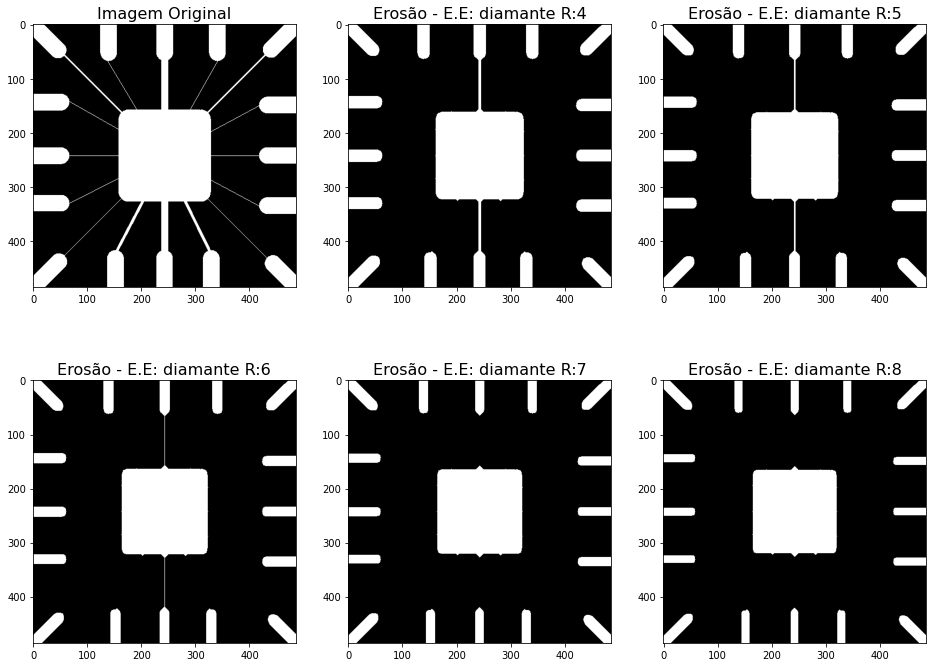

In [13]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 7
# carregando a imagem na escala de cinza
im_wirebond = cv2.imread('imagens/wirebond_mask.tif')
im_wirebond = cv2.cvtColor(im_wirebond, cv2.COLOR_BGR2GRAY)
im_wirebond = cv2.threshold(im_wirebond, 127.5, 255, cv2.THRESH_BINARY)[1]

# utilizando o elemento estruturante no formato de diamante e variando o raio desse elemento  
kernel1 = skimage.morphology.diamond(4)
kernel2 = skimage.morphology.diamond(5)
kernel3 = skimage.morphology.diamond(6)
kernel4 = skimage.morphology.diamond(7)
kernel5 = skimage.morphology.diamond(8)

# aplicando a erosão na imagem com os diversos elementos estruturantes gerados  
erode_im1 = cv2.erode(im_wirebond, kernel1, iterations=1)
erode_im2 = cv2.erode(im_wirebond, kernel2, iterations=1)
erode_im3 = cv2.erode(im_wirebond, kernel3, iterations=1)
erode_im4 = cv2.erode(im_wirebond, kernel4, iterations=1)
erode_im5 = cv2.erode(im_wirebond, kernel5, iterations=1)

fig, axs = plt.subplots(nrows = 2, ncols = 3, figsize = (16, 12))

# primeira figura da subplotagem
axs[0, 0].imshow(im_wirebond, cmap = "gray")
axs[0, 0].set_title("Imagem Original", fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(erode_im1, cmap = "gray")
axs[0, 1].set_title("Erosão - E.E: diamante R:4", fontsize = 16)

# terceira figura da subplotagem
axs[0, 2].imshow(erode_im2, cmap = "gray")
axs[0, 2].set_title("Erosão - E.E: diamante R:5", fontsize = 16)

# quarta figura da subplotagem
axs[1, 0].imshow(erode_im3, cmap = "gray")
axs[1, 0].set_title("Erosão - E.E: diamante R:6", fontsize = 16)

# quinta figura da subplotagem
axs[1, 1].imshow(erode_im4, cmap = "gray")
axs[1, 1].set_title("Erosão - E.E: diamante R:7", fontsize = 16)

# sexta figura da subplotagem
axs[1, 2].imshow(erode_im5, cmap = "gray")
axs[1, 2].set_title("Erosão - E.E: diamante R:8", fontsize = 16)

## <span style='color:green'>Respostas da Questão 7:</span>

* Ao realizar a erosão na imagem acima, foi possível observar a influência do elemento estruturante (kernel) para cada um dos resultados obtidos. O tamanho do raio desse elemento implica nas saídas de cada uma das imagens. Quanto maior for as dimensões do elemento estruturante, mas partículas são erodidas, considerando que as partículas possuem um tamanho menor em relação ao kernel.

### Abertura e Fechamento

A partir de um elemento estruturante é possível utilizar funções do OpenCV para realizar as transformações morfológicas de abertura e fechamento a partir de uma mesma função. Sua sintaxe é: 

* `dst_img = cv2.morphologyEx(src_img, FLAG, kernel)`       

* **Descrição:**
    * **dst_img** representa a imagem de saída;
    * **src_img** representa a imagem de entrada;
    * **kernel** representa o elemento estruturante;
    * **FLAG** é um parâmetro que indica a transformação realizada, pode ser:
        * **cv2.MORPH_OPEN** realiza uma operação de abertura;
        * **cv2.MORPH_CLOSE** realiza uma operação de fechamento;
        * **cv2.MORPH_GRADIENT** realiza uma operação de gradiente morfológico (diferença entre as versões dilatada e erodida de uma imagem);
        * **cv2.MORPH_TOPHAT** realiza uma operação de Tophat (diferença entre a imagem original e sua versão após abertura);
        * **cv2.MORPH_BLACKHAT** realiza uma operação de Blackhat (diferença entre a versão da imagem após fechamento e a original);

## <span style='color:blue'>Questão 8: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Aplique os seguintes filtros morfológicos na imagem "**shapes.tif**". Comente os resultados encontrados em todos os itens acima.
    * Abertura, utilizando um elemento estruturante quadrado (square) de altura 10.
    * Fechamento, utilizando um elemento estruturante quadrado de altura 10.
    * Uma abertura seguida de um fechamento, um elemento estruturante quadrado de altura 10.
    * Repetir o item anterior variando a altura do elemento estruturante para 5 e depois para 15. Analise os resultados encontrados.

Text(0.5, 0, 'E.E - Quadrado H:10')

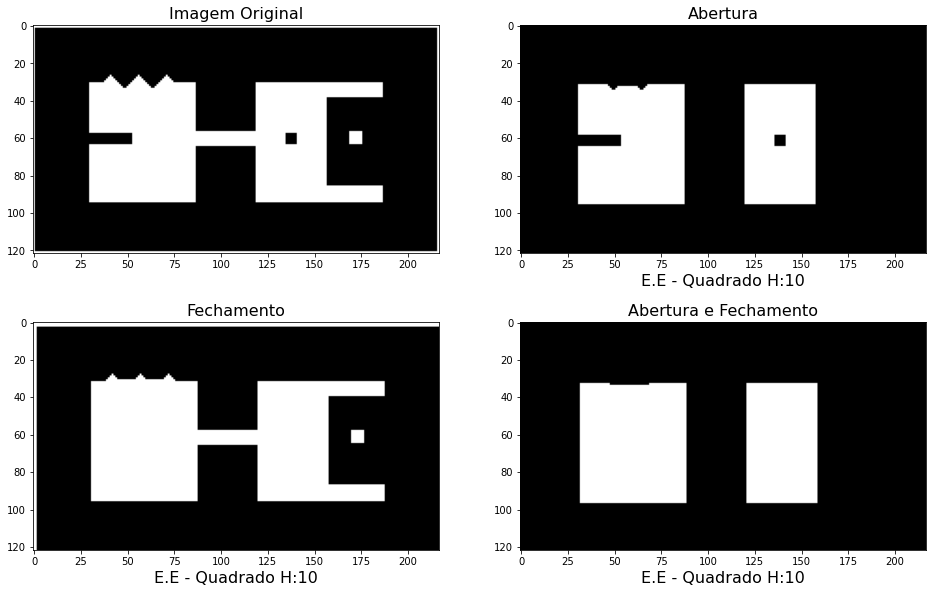

In [14]:
# IMPLEMENTE O SEU CÓDIGO AQUI --> QUESTÃO 7
# carregando a imagem em escala de cinza
shapes_im = cv2.imread('imagens/shapes.tif')
shapes_im = cv2.cvtColor(shapes_im, cv2.COLOR_BGR2GRAY)
shapes_im = cv2.threshold(shapes_im, 127.5, 255, cv2.THRESH_BINARY)[1]

# configurando os elementos estruturantes 
square_kernel1 = skimage.morphology.square(10)
square_kernel2 = skimage.morphology.square(5)
square_kernel3 = skimage.morphology.square(15)

# aplicando os procedimentos de morfologia matemática nas imagens
im1 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel1)
im2 = cv2.morphologyEx(shapes_im, cv2.MORPH_CLOSE, square_kernel1)
im3 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel1) 
im3 = cv2.morphologyEx(im3, cv2.MORPH_CLOSE, square_kernel1)  

fig, axs = plt.subplots(nrows = 2, ncols = 2, figsize = (16, 10))
 
# primeira figura da subplotagem
axs[0, 0].imshow(shapes_im, cmap = "gray")
axs[0, 0].set_title("Imagem Original", fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(im1, cmap = "gray")
axs[0, 1].set_title("Abertura", fontsize = 16)
axs[0, 1].set_xlabel('E.E - Quadrado H:10', fontsize = 16) 

# terceira figura da subplotagem
axs[1, 0].imshow(im2, cmap="gray")
axs[1, 0].set_title("Fechamento", fontsize = 16)
axs[1, 0].set_xlabel('E.E - Quadrado H:10', fontsize = 16)

# quarta figura da subplotagem
axs[1, 1].imshow(im3, cmap = "gray")
axs[1, 1].set_title("Abertura e Fechamento", fontsize = 16)
axs[1, 1].set_xlabel('E.E - Quadrado H:10', fontsize = 16) 

Text(0.5, 0, 'E.E - Quadrado H:15')

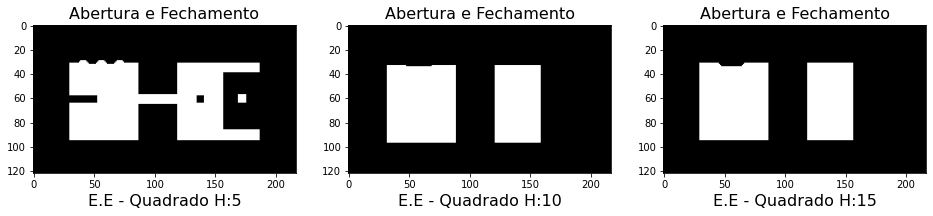

In [15]:
# IMPLEMENTE O SEU CÓDIGO AQUI --> QUESTÃO 7 - VARIAÇÃO DO ELEMENTO ESTRUTURANTE
# aplicando os procedimentos de morfologia matemática nas imagens
im4 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel2) 
im4 = cv2.morphologyEx(im4, cv2.MORPH_CLOSE, square_kernel2)  
im5 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel3) 
im5 = cv2.morphologyEx(im5, cv2.MORPH_CLOSE, square_kernel3)  

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16,12))

# primeira figura da subplotagem
axs[0].imshow(im4, cmap="gray")
axs[0].set_title("Abertura e Fechamento", fontsize = 16)
axs[0].set_xlabel('E.E - Quadrado H:5', fontsize = 16)

# primeira figura da subplotagem
axs[1].imshow(im3, cmap="gray")
axs[1].set_title("Abertura e Fechamento", fontsize = 16)
axs[1].set_xlabel('E.E - Quadrado H:10', fontsize = 16)

# primeira figura da subplotagem
axs[2].imshow(im5, cmap="gray")
axs[2].set_title("Abertura e Fechamento", fontsize = 16)
axs[2].set_xlabel('E.E - Quadrado H:15', fontsize = 16) 

## <span style='color:green'>Respostas da Questão 8:</span>

* A abertura na imagem realiza uma suavização do contorno, retira intruzões, tornando menos agudos os cantos.
* O fechamento na imagem suaviza seções do contorno, preenchimento de buracos e união de furos e falhas do contorno.
* O procedimento de abertura sucedido de fechamento é equivalmente a suavizar os elementos da imagem e sequencialmente corrigir as falhas do contorno.
* O tamanho do elemento estruturante influência na forma como os elementos tem seus cantos suavizados seguidos da correção de falhas de contorno. Quanto maior for o elemento estruturante, mais partículas são modificadas na imagem, transformando-as mais bruscamente.

## <span style='color:blue'>Questão 9: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Aplique os seguintes filtros morfológicos na imagem "**finger.jpg**". Comente os resultados encontrados em todos os itens.
    * Abertura, utilizando um elemento estruturante em formato de disco de raio 1.
    * Fechamento, utilizando um elemento estruturante em formato de disco de raio 1.
    * Uma abertura seguida de um fechamento com um elemento estruturante em formato de disco de raio 1.
    * Um fechamento seguido de uma abertura com um elemento estruturante em formato de disco de raio 1.

Text(0.5, 0, 'E.E - Disco R:1')

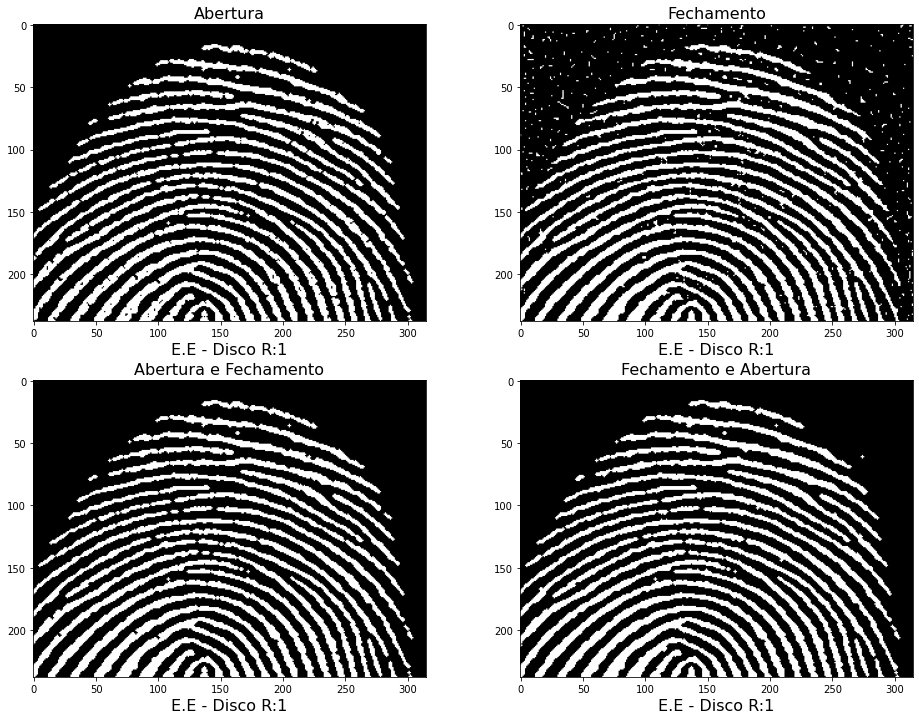

In [16]:
# IMPLEMENTE O SEU CÓDIGO AQUI --> QUESTÃO 9
# carregando a imagem em escala de cinza
finger_im = cv2.imread('imagens/finger.jpg')
finger_im = cv2.cvtColor(finger_im, cv2.COLOR_BGR2GRAY)

# configurando o elemento estruturante 
disk_kernel = skimage.morphology.disk(1) 

# aplicando os procedimentos de morfologia matemática nas imagens
im1 = cv2.morphologyEx(finger_im, cv2.MORPH_OPEN, disk_kernel) 
im2 = cv2.morphologyEx(finger_im, cv2.MORPH_CLOSE, disk_kernel) 
im3 = cv2.morphologyEx(finger_im, cv2.MORPH_OPEN, disk_kernel) 
im3 = cv2.morphologyEx(im3, cv2.MORPH_CLOSE, disk_kernel) 
im4 = cv2.morphologyEx(finger_im, cv2.MORPH_CLOSE, disk_kernel) 
im4 = cv2.morphologyEx(im4, cv2.MORPH_OPEN, disk_kernel)  

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16,12))

# primeira figura da subplotagem
axs[0, 0].imshow(im1, cmap="gray")
axs[0, 0].set_title("Abertura", fontsize = 16)
axs[0, 0].set_xlabel('E.E - Disco R:1', fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(im2, cmap="gray")
axs[0, 1].set_title("Fechamento", fontsize = 16)
axs[0, 1].set_xlabel('E.E - Disco R:1', fontsize = 16)

# terceira figura da subplotagem
axs[1, 0].imshow(im3, cmap="gray")
axs[1, 0].set_title("Abertura e Fechamento", fontsize = 16)
axs[1, 0].set_xlabel('E.E - Disco R:1', fontsize = 16)

# quarta figura da subplotagem
axs[1, 1].imshow(im4, cmap="gray")
axs[1, 1].set_title("Fechamento e Abertura", fontsize = 16)
axs[1, 1].set_xlabel('E.E - Disco R:1', fontsize = 16)  

## <span style='color:green'>Respostas da Questão 9:</span>

* Na primeira imagem, o procedimento de abertura permitiu extrair a maioria dos ruídos na imagem biométrica do polegar.
* Na segunda imagem, o procedimento de fechamento corrigiu as falhas presentes nos traços da digital do polegar, mas não removeu os ruídos presentes na imagem.
* Comparando a terceira imagem com a quarta imagem, o procedimento de realizar a abertura sucedida de fechamento na digital do polegar permitiu obter a melhor imagem dentre as 4 analisadas. Isso porque os ruídos foram removidos e a qualidade dos traços foram preservadas, permitindo uma imagem mais adequada para identificação biométrica do usuário.

![gif2](https://user-images.githubusercontent.com/58775072/142712675-08fa8843-9a5e-4109-a94a-8ca2d60e4fa8.gif)